**Eye-Tracking & Neurocognitive Intelligence | Eye-Tracking Foundations & Signal Analysis | Presented by: Reza Saadatyar (2026)**

**06 | Detector Sensitivity and Vendor-Label Agreement**

![Conceptual workflow for stage 06](../../images/06_detector_sensitivity_and_vendor_reference.svg)

**Objective:** Test how I-VT threshold choices change event assignments and reported vendor-reference agreement.

**Dataset:** Notebook 02 motion representation and Notebook 03 original vendor comparison.

**Notebook scope:** An additional robustness analysis on existing prepared data; no raw re-download or training.

**Execution status:** Source code prepared. No original-data results are claimed until this notebook is executed with the specified release.


**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**

In [ ]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("eye_tracking_foundations")

# ----------------- 2. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 3. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure
from core.output_download import download_outputs_from_colab

# ------------------------ 4. Study Research Utilities ------------------------
from core.stage_outputs import ensure_stage_inputs
from gaze_source import read_stage
from eye_events import ivt_labels, label_agreement

# --------------------- 5. Output and Presentation Setup ----------------------
output_dir = root / "eye_tracking_foundations" / "output"
output_dir.mkdir(parents=True, exist_ok=True)
plot_style(
    font_family="DejaVu Sans", title_size=12.5,
    title_weight="normal", label_size=11.5,
    label_weight="normal", tick_size=11,
    legend_size=10, figure_dpi=100, figure_size=(10, 4),
)
print("Current outputs:", output_dir)


Repository updated.
Current outputs: /content/Eye-Tracking-Neurocognitive-Intelligence/eye_tracking_foundations/output


**02. Recover Prepared Motion and Reference Coverage**

Read the named current outputs from earlier stages. This notebook revisits
*algorithm thresholds only*, which is new sensitivity analysis rather than
repeating data acquisition, preprocessing or feature construction.


In [3]:
# ============ 02. Recover Prepared Motion and Reference Coverage =============

ensure_stage_inputs(output_dir,2,("02_preprocessed_samples.csv",))
ensure_stage_inputs(output_dir,3,("03_vendor_agreement.csv",))
prepared=read_stage(output_dir/"02_preprocessed_samples.csv",
                    ("record_id","participant_id","n","velocity_dva_s","segment_id","lab"))
reference=read_stage(output_dir/"03_vendor_agreement.csv",
                     ("record_id","vendor_coverage_fraction"))


**03. Evaluate Predefined Velocity Thresholds**

Compare 20, 30 and 40 dva/s only as an exploratory sensitivity grid.
These were not selected to maximise vendor agreement. Unknown samples
remain unknown; vendor labels are not independent gold standard.


In [4]:
# ================ 03. Evaluate Predefined Velocity Thresholds ================

THRESHOLDS=(20.0,30.0,40.0)
rows=[]
for rid,part in prepared.groupby("record_id",sort=True):
    part=part.sort_values("sample_index").reset_index(drop=True)
    for threshold in THRESHOLDS:
        pred=ivt_labels(part,threshold_dva_s=threshold)
        agreement=label_agreement(part,pred)
        rows.append({
            "record_id":rid, "participant_id":str(part.participant_id.iloc[0]).zfill(3),
            "task":part.task.iloc[0], "threshold_dva_s":threshold,
            "predicted_fixation_fraction":float(np.mean(pred=="fixation")),
            "predicted_saccade_fraction":float(np.mean(pred=="saccade")),
            "unknown_fraction":float(np.mean(pred=="unknown")),
            **agreement,
        })
sensitivity=pd.DataFrame(rows)
sensitivity.to_csv(output_dir/"06_sensitivity.csv",index=False)
display(sensitivity)


,record_id,participant_id,task,threshold_dva_s,predicted_fixation_fraction,predicted_saccade_fraction,unknown_fraction,eligible_samples,vendor_coverage_fraction,predicted_evaluable_fraction,sample_agreement
0,S_1001_S1_FXS,001,FXS,20.0,0.245871,0.014459,0.739670,3925,0.999469,0.260330,0.976306
1,S_1001_S1_FXS,001,FXS,30.0,0.924454,0.008888,0.066658,14065,0.999469,0.932878,0.995308
2,S_1001_S1_FXS,001,FXS,40.0,0.952179,0.006168,0.041653,14442,0.999469,0.957883,0.996538
3,S_1001_S1_HSS,001,HSS,20.0,0.147336,0.112252,0.740412,26296,0.999921,0.259588,0.944744
4,S_1001_S1_HSS,001,HSS,30.0,0.651191,0.103930,0.244879,76493,0.999921,0.755121,0.985018
...,...,...,...,...,...,...,...,...,...,...,...
115,S_1010_S1_RAN,010,RAN,30.0,0.731129,0.085079,0.183791,82504,0.999921,0.816209,0.977771
116,S_1010_S1_RAN,010,RAN,40.0,0.874122,0.076433,0.049445,96084,0.999921,0.950555,0.984191
117,S_1010_S1_TEX,010,TEX,20.0,0.079388,0.155658,0.764955,14173,0.999867,0.235045,0.824384
118,S_1010_S1_TEX,010,TEX,30.0,0.637705,0.133684,0.228611,46514,0.999867,0.771389,0.957325


**04. Inspect Conditional Agreement and Coverage**

When some tasks lack vendor labels, their agreement is undefined, not zero.
Compare coverage beside conditional sample agreement, without describing
vendor agreement as event-boundary accuracy or clinical validation.


In [5]:
# ============== 04. Inspect Conditional Agreement and Coverage ===============

summary=sensitivity.groupby("threshold_dva_s",as_index=False).agg(
    n_records=("record_id","size"),
    mean_predicted_fixation_fraction=("predicted_fixation_fraction","mean"),
    mean_unknown_fraction=("unknown_fraction","mean"),
    mean_conditional_vendor_agreement=("sample_agreement","mean"),
)
summary.to_csv(output_dir/"06_sensitivity_summary.csv",index=False)
display(summary)


,threshold_dva_s,n_records,mean_predicted_fixation_fraction,mean_unknown_fraction,mean_conditional_vendor_agreement
0,20.0,40,0.285257,0.622422,0.909743
1,30.0,40,0.612272,0.305744,0.981307
2,40.0,40,0.786466,0.137801,0.987844


**05. Visualise Threshold Sensitivity**

Illustrate the proportion labelled fixation under different fixed
thresholds; a shift in proportions is not an improvement by itself.


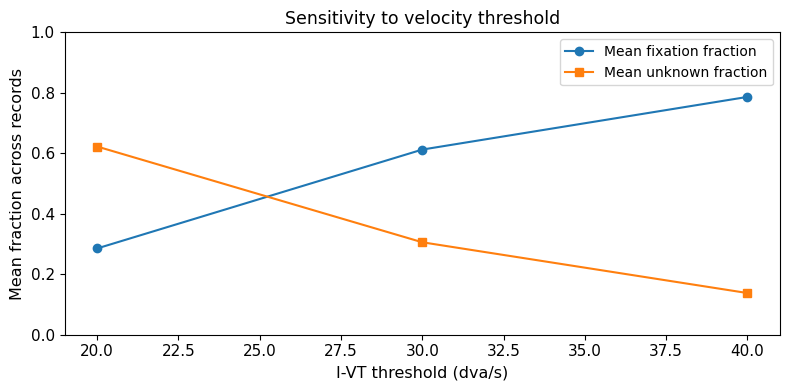

In [6]:
# ==================== 05. Visualise Threshold Sensitivity ====================

fig,ax=plt.subplots(figsize=(8,4))
ax.plot(summary.threshold_dva_s,summary.mean_predicted_fixation_fraction,
        marker="o",label="Mean fixation fraction")
ax.plot(summary.threshold_dva_s,summary.mean_unknown_fraction,
        marker="s",label="Mean unknown fraction")
ax.set(xlabel="I-VT threshold (dva/s)",ylabel="Mean fraction across records",
       ylim=(0,1),title="Sensitivity to velocity threshold")
ax.legend()
fig.tight_layout()
save_figure(fig,output_dir/"06_threshold_sensitivity.png")
plt.show()


**06. Document Robustness Boundaries and Download**

The sensitivity grid cannot validate physiological event identity. Future
work may compare an adaptive method or expert-coded events when available;
no such performance is claimed here.


In [7]:
# ============== 06. Document Robustness Boundaries and Download ==============

print("Fixed thresholds evaluated:",THRESHOLDS)
download_outputs_from_colab("eye_tracking_foundations/output","06")


Fixed thresholds evaluated: (20.0, 30.0, 40.0)
------------------------------------------------------------------------
Notebook 06
Files packaged: 3
  + 06_sensitivity.csv
  + 06_sensitivity_summary.csv
  + 06_threshold_sensitivity.png
Download ZIP from Colab Contents: /content/eye_tracking_foundations_Notebook_06_Outputs.zip
